## B6 · Reshaping and combining DataFrames

concat, merge, wide-to-long (melt) and long-to-wide (pivot).

In [549]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# Plot defaults: wide 16:9 figures, sharp ("retina") output and slightly smaller text
%config InlineBackend.figure_format = "retina"
plt.rcParams.update({
    "figure.figsize": (6.4, 3.6),
    "figure.dpi": 100,
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
})

# Same data as sns.load_dataset('penguins'), saved locally so it works offline
df_penguins = pd.read_csv("data/penguins.csv")

# Small tables used throughout this sheet
df1 = pd.DataFrame({"ID": [101, 102], "Name": ["Ana", "Bo"]})
df2 = pd.DataFrame({"ID": [103, 104], "Name": ["Cy", "Di"]})
df_grades_wide = pd.DataFrame({
    "ID": [101, 102, 103],
    "Name": ["Ana", "Bo", "Cy"],
    "Math": [70, 85, 60],
    "Art": [90, 65, 72],
})
df_left = pd.DataFrame({"Team": ["Real", "City", "Inter"], "Player": ["Vini", "Silva", "Lau"]})
df_right = pd.DataFrame({"Team": ["Real", "City", "Spurs"], "Country": ["ES", "UK", "UK"]})

### Combining with concat

#### Stacking rows

**B6.01**

`pd.concat([df1, df2], axis=0, ignore_index=True)`

The `pd.concat()` function with `axis=0` allows us to stack tables one under another. It is useful when the same type of data has been collected in several files or batches. Alternatively, `pd.merge` joins tables side by side by a key instead of stacking them.

`ignore_index=True` renumbers the result 0…n−1; without it the original labels repeat.

In [550]:
# display example data
df1

,ID,Name
0,101,Ana
1,102,Bo


In [551]:
# display example data
df2

,ID,Name
0,103,Cy
1,104,Di


In [552]:
pd.concat([df1, df2], axis=0, ignore_index=True)

,ID,Name
0,101,Ana
1,102,Bo
2,103,Cy
3,104,Di


In [553]:
pd.concat([df1, df2])      # without ignore_index: the labels 0, 1 repeat

,ID,Name
0,101,Ana
1,102,Bo
0,103,Cy
1,104,Di


*See also:* Placing tables side by side (B6) · Combining tables with different columns (B6) · Discarding the old index (B2) · Checking a DataFrame after each step (B1)

#### Placing tables side by side

**B6.02**

`pd.concat([df1, df3], axis=1)`

The `pd.concat()` function with `axis=1` allows us to put tables next to each other, matching rows by their index. It is useful when columns for the same rows come from different sources. Alternatively, `pd.merge` matches on a key column rather than on the index.

In [554]:
# display the example data
df_names = pd.DataFrame({"Name": ["Ana", "Bo", "Cy"]})
df_grades = pd.DataFrame({"Grade": ["A", "B", "C"]})
df_grades

,Grade
0,A
1,B
2,C


In [555]:
pd.concat([df_names, df_grades], axis=1)

,Name,Grade
0,Ana,A
1,Bo,B
2,Cy,C


Rows are matched on the **index**, so a different index leaves gaps:

In [556]:
df_grades2 = pd.DataFrame({"Grade": ["A", "B"]}, index=[0, 5])

In [557]:
# display example dataframe
df_grades2

,Grade
0,A
5,B


In [558]:
pd.concat([df_names, df_grades2], axis=1)

,Name,Grade
0,Ana,A
1,Bo,NaN
2,Cy,NaN
5,NaN,B


*See also:* Stacking rows (B6) · Setting a column as the index (B2)

#### Combining tables with different columns

**B6.03**

`pd.concat with different columns`

Concatenating tables with different columns allows us to keep every column, with `NaN` where a table has no data. It is useful when tables come from different sources and do not share every column, because no error is raised and the missing values are filled with NaN. Alternatively, `join="inner"` keeps only the columns both tables share.

In [559]:
# display the example data
df_extra = pd.DataFrame({"ID": [105], "Email": ["e@x.org"]})
df_extra

,ID,Email
0,105,e@x.org


In [560]:
pd.concat([df1, df_extra], ignore_index=True)

,ID,Name,Email
0,101,Ana,NaN
1,102,Bo,NaN
2,105,NaN,e@x.org


In [561]:
pd.concat([df1, df_extra], ignore_index=True, join="inner")    # only the shared column

,ID
0,101
1,102
2,105


*See also:* Stacking rows (B6) · Counting missing values (B5) · Filling missing values (B5)

### Combining with merge

#### Merging on a key column

**B6.04**

`pd.merge(df_left, df_right, on='key')`

The `pd.merge()` function allows us to combine two tables by matching rows on a key column. It is useful when information about the same things is held in separate tables. Alternatively, `concat(axis=1)` matches on the index instead.

By default only keys found in **both** tables are kept (an *inner* join).

In [562]:
# display example data
df_left

,Team,Player
0,Real,Vini
1,City,Silva
2,Inter,Lau


In [563]:
# display example data
df_right

,Team,Country
0,Real,ES
1,City,UK
2,Spurs,UK


In [564]:
pd.merge(df_left, df_right, on="Team")      # Inter and Spurs are dropped

,Team,Player,Country
0,Real,Vini,ES
1,City,Silva,UK


*See also:* Stacking rows (B6) · Choosing the join type (B6) · Placing tables side by side (B6) · Merging on keys with different names (B6) · Checking a DataFrame after each step (B1)

#### Choosing the join type

**B6.05**

`pd.merge(df_left, df_right, how='left' / 'right' / 'outer')`

The `how=` argument allows us to decide which rows to keep when the keys do not all match. It is useful for keeping every row from one table (`left`, `right`) or from both (`outer`). Alternatively, the default `inner` keeps only the matches.

- `inner`: only keys in both tables.
- `left`: every row of the left table.
- `right`: every row of the right table.
- `outer`: everything from both.

In [565]:
# display example data
df_left

,Team,Player
0,Real,Vini
1,City,Silva
2,Inter,Lau


In [566]:
# display example data
df_right

,Team,Country
0,Real,ES
1,City,UK
2,Spurs,UK


In [567]:
pd.merge(df_left, df_right, on="Team", how="left")       # every row of the left table

,Team,Player,Country
0,Real,Vini,ES
1,City,Silva,UK
2,Inter,Lau,NaN


In [568]:
pd.merge(df_left, df_right, on="Team", how="outer")      # everything from both tables

,Team,Player,Country
0,City,Silva,UK
1,Inter,Lau,NaN
2,Real,Vini,ES
3,Spurs,NaN,UK


*See also:* Merging on a key column (B6) · Showing where each row came from (B6) · Counting missing values (B5)

#### Merging on keys with different names

**B6.06**

`pd.merge(l, r, left_on='a', right_on='b')`

***(non-examinable)***

The `left_on=` and `right_on=` arguments allow us to merge when the key column has a different name in each table. It is useful for tables from different sources. Alternatively, rename one column first so both have the same name.

The right-hand table below names its key column `Club` instead of `Team`:

In [569]:
df_right2 = df_right.rename(columns={"Team": "Club"})
df_right2

,Club,Country
0,Real,ES
1,City,UK
2,Spurs,UK


In [570]:
pd.merge(df_left, df_right2, left_on="Team", right_on="Club")

,Team,Player,Club,Country
0,Real,Vini,Real,ES
1,City,Silva,City,UK


*See also:* Merging on a key column (B6) · Renaming columns with a dictionary (B2) · Dropping columns (B2)

#### Showing where each row came from

**B6.07**

`pd.merge(..., indicator=True)`

***(non-examinable)***

The `indicator=True` option allows us to add a column saying whether each row came from the left table, the right table or both. It is useful for spotting unmatched records. Alternatively, compare the key columns with `isin()`.

In [571]:
# display example data
df_left

,Team,Player
0,Real,Vini
1,City,Silva
2,Inter,Lau


In [572]:
# display example data
df_right

,Team,Country
0,Real,ES
1,City,UK
2,Spurs,UK


In [573]:
pd.merge(df_left, df_right, on="Team", how="outer", indicator=True)

,Team,Player,Country,_merge
0,City,Silva,UK,both
1,Inter,Lau,NaN,left_only
2,Real,Vini,ES,both
3,Spurs,NaN,UK,right_only


*See also:* Choosing the join type (B6) · Filtering with `~`, `isin()` and `between()` (B3) · Counting each category (B5)

### Making long tables

#### Reshaping wide to long with `set_index` and `melt`

**B6.08**

`set_index → melt(var_name, value_name, ignore_index=False) → reset_index`

The `set_index` → `melt` → `reset_index` sequence allows us to turn one column per measurement into one row per measurement. It is useful because seaborn and many statistical tools need *long* format. Alternatively, `melt(id_vars=...)` does it in one step.

Put the identifier columns into the index, melt the rest, then restore the index as columns.

In [574]:
# display the example data
df_grades_wide

,ID,Name,Math,Art
0,101,Ana,70,90
1,102,Bo,85,65
2,103,Cy,60,72


Chaining the steps in brackets (the spaces immediately inside the outer `( … )` make them visible):

In [575]:
df_long = ( df_grades_wide
            .set_index(["ID", "Name"])
            .melt(var_name="Subject", value_name="Grade", ignore_index=False)
            .reset_index() )
df_long

,ID,Name,Subject,Grade
0,101,Ana,Math,70
1,102,Bo,Math,85
2,103,Cy,Math,60
3,101,Ana,Art,90
4,102,Bo,Art,65
5,103,Cy,Art,72


In [576]:
df_long = df_grades_wide.set_index(["ID", "Name"])                                       # identifiers into the index
df_long = df_long.melt(var_name="Subject", value_name="Grade", ignore_index=False)       # wide to long
df_long = df_long.reset_index()                                                          # index back to columns
df_long

,ID,Name,Subject,Grade
0,101,Ana,Math,70
1,102,Bo,Math,85
2,103,Cy,Math,60
3,101,Ana,Art,90
4,102,Bo,Art,65
5,103,Cy,Art,72


Rename the columns **before** melting so the values in the long table read well: here day numbers instead of `bp_day1`.

In [577]:
df_bp = pd.read_csv("data/bp_experiment2.csv")

In [578]:
# display the first rows of the loaded data
df_bp.head()

,id,gender,bp_day1,bp_day30
0,1,f,153.0,150.0
1,2,f,143.0,139.0
2,3,m,151.0,156.0
3,4,f,159.0,151.0
4,5,m,128.0,124.0


In [579]:
df_bp_long = ( df_bp
               .set_index(["id", "gender"])
               .rename(columns={"bp_day1": 1, "bp_day30": 30})
               .melt(var_name="day", value_name="bp", ignore_index=False)
               .reset_index() )
df_bp_long.head()

,id,gender,day,bp
0,1,f,1,153.0
1,2,f,1,143.0
2,3,m,1,151.0
3,4,f,1,159.0
4,5,m,1,128.0


In [580]:
df_bp_long = df_bp.set_index(["id", "gender"])
df_bp_long = df_bp_long.rename(columns={"bp_day1": 1, "bp_day30": 30})
df_bp_long = df_bp_long.melt(var_name="day", value_name="bp", ignore_index=False)
df_bp_long = df_bp_long.reset_index()
df_bp_long.head()

,id,gender,day,bp
0,1,f,1,153.0
1,2,f,1,143.0
2,3,m,1,151.0
3,4,f,1,159.0
4,5,m,1,128.0


**Why bother?** Seaborn (and most statistical tools) expect *long* data: one column for the group and one for the value. The long table plots in one call:

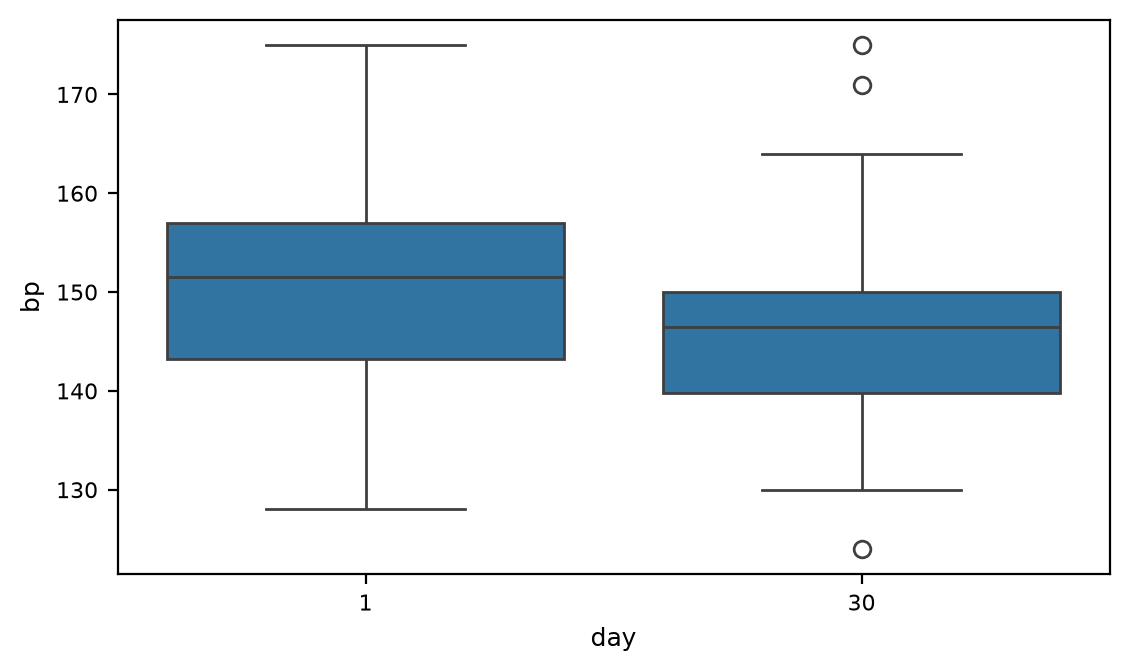

In [581]:
sns.boxplot(data=df_bp_long, x="day", y="bp");

*See also:* Reshaping wide to long with `melt` and `id_vars` (B6) · Setting a multi-level index (B2) · Renaming columns with a dictionary (B2) · Reshaping long to wide with `set_index` and `pivot` (B6)

#### Reshaping wide to long with `melt` and `id_vars`

**B6.09**

`df.melt(id_vars=ids, var_name='var', value_name='value')`

***(non-examinable)***

The `melt(id_vars=...)` method allows us to reshape wide to long without the index steps. It is useful when a few identifier columns stay as they are and all other columns are measurements. Alternatively, the course method with `set_index` achieves the same result.

In [582]:
# display the example data
df_grades_wide

,ID,Name,Math,Art
0,101,Ana,70,90
1,102,Bo,85,65
2,103,Cy,60,72


In [583]:
df_grades_wide.melt(id_vars=["ID", "Name"], var_name="Subject", value_name="Grade")

,ID,Name,Subject,Grade
0,101,Ana,Math,70
1,102,Bo,Math,85
2,103,Cy,Math,60
3,101,Ana,Art,90
4,102,Bo,Art,65
5,103,Cy,Art,72


*See also:* Reshaping long to wide with `set_index` and `pivot` (B6)

### Making wide tables

#### Reshaping long to wide with `set_index` and `pivot`

**B6.10**

`set_index → pivot(columns, values) → reset_index().rename_axis(None, axis=1)`

The `set_index` → `pivot` → `reset_index` sequence allows us to turn one row per measurement back into one column per measurement. It is useful for tables that people read, or for calculating differences between columns. Alternatively, `pivot(index=...)` does it in one step.

In [584]:
df_long = df_grades_wide.melt(id_vars=["ID", "Name"], var_name="Subject", value_name="Grade")
df_long

,ID,Name,Subject,Grade
0,101,Ana,Math,70
1,102,Bo,Math,85
2,103,Cy,Math,60
3,101,Ana,Art,90
4,102,Bo,Art,65
5,103,Cy,Art,72


In [585]:
df_wide = ( df_long
            .set_index(["ID", "Name"])
            .pivot(columns="Subject", values="Grade")
            .reset_index()
            .rename_axis(None, axis=1) )
df_wide

,ID,Name,Art,Math
0,101,Ana,90,70
1,102,Bo,65,85
2,103,Cy,72,60


In [586]:
df_wide = df_long.set_index(["ID", "Name"])
df_wide = df_wide.pivot(columns="Subject", values="Grade")
df_wide = df_wide.reset_index()                  # index back to columns
df_wide = df_wide.rename_axis(None, axis=1)      # remove the leftover 'Subject' label
df_wide

,ID,Name,Art,Math
0,101,Ana,90,70
1,102,Bo,65,85
2,103,Cy,72,60


*See also:* Reshaping long to wide with `pivot` and `index` (B6) · Naming the index and column axes (B2) · Reshaping wide to long with `set_index` and `melt` (B6) · Summarising into a grid with `pivot_table` (B9)

#### Reshaping long to wide with `pivot` and `index`

**B6.11**

`df.pivot(index='ID', columns='Exam', values='Grade')`

***(non-examinable)***

The `pivot(index=, columns=, values=)` method allows us to reshape long to wide in one call. It is useful when there is only one identifier column. Alternatively, `pivot_table` handles repeated entries by averaging them.

In [587]:
df_long = df_grades_wide.melt(id_vars=["ID", "Name"], var_name="Subject", value_name="Grade")
df_long

,ID,Name,Subject,Grade
0,101,Ana,Math,70
1,102,Bo,Math,85
2,103,Cy,Math,60
3,101,Ana,Art,90
4,102,Bo,Art,65
5,103,Cy,Art,72


In [588]:
df_long.pivot(index="ID", columns="Subject", values="Grade")

Subject,Art,Math
ID,,
101,90,70
102,65,85
103,72,60


*See also:* Reshaping long to wide with `set_index` and `pivot` (B6) · Summarising into a grid with `pivot_table` (B9) · Reshaping wide to long with `melt` and `id_vars` (B6)